# 02 · Fine-Tune a PII Token Classifier
**RedactNER: Local PII Redaction for Word Documents**

This notebook fine-tunes one transformer encoder for token classification over the 13 PII categories,
using the splits produced by `01_data_preparation.ipynb`. It is parameterised by `MODEL_NAME`, `RUN_NAME`
and `SEED`, and is executed once per model and seed with an identical training recipe.

| Role | Model | Parameters | Seeds |
|---|---|---|---|
| Main Model | `microsoft/deberta-v3-base` | 184M | 42, 7 |
| Baseline | `FacebookAI/roberta-base` | 125M | 42, 7 |
| Baseline | `answerdotai/ModernBERT-base` | 150M | 42, 7 |
| Scale Experiment | `answerdotai/ModernBERT-large` | 396M | 42 |

Two seeds per base model show how much of a difference between models is due to chance. The large model
tests whether a bigger encoder transfers better to unseen documents.

**Implementation Details**
* **Character-Exact Alignment.** A token receives the label of the entity that covers any of its
  non-space characters. It is tagged `B-` when it contains the first character of the entity and `I-`
  otherwise. Whitespace-only and special tokens are ignored, which keeps the labels independent of
  tokenizer conventions such as SentencePiece offsets that include the leading space.
* **Sliding Windows.** Long documents are split into 512-token windows that overlap by 128 tokens.
* **Mixed Precision.** Training uses bf16, which is numerically stable for DeBERTa-v3, together with a
  linear learning-rate schedule and warm-up.
* **Checkpoint Selection.** The model is evaluated on the development set after every epoch and the best
  epoch is kept.

In [1]:
MODEL_NAME = "microsoft/deberta-v3-base"
RUN_NAME = "deberta-v3-base_s42"
MAX_LEN = 512
STRIDE = 128
EPOCHS = 2
MAX_STEPS = -1          # a positive value limits training to this many steps (overrides EPOCHS)
LR = 3e-5
BATCH = 4
GRAD_ACCUM = 4
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
SEED = 42
GRADIENT_CHECKPOINTING = False  # recompute activations in the backward pass to save memory
OPTIM = "adamw_torch"   # "adamw_bnb_8bit" keeps the optimiser state in 8 bits (requires bitsandbytes)
SMOKE = False           # short run that checks the pipeline and measures throughput
DATA_DIR_NAME = "processed"
PROJECT_DIR = ".."

In [2]:
# Parameters
SEED = 42
GRADIENT_CHECKPOINTING = True
MODEL_NAME = "answerdotai/ModernBERT-large"
RUN_NAME = "modernbert-large_s42"
OPTIM = "adamw_bnb_8bit"


## 0. Setup and Environment Check

In [3]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.56,<5", "datasets>=3.0",
                    "accelerate", "seqeval", "sentencepiece", "protobuf"], check=True)
    PROJECT_DIR = "/content/redactner"

import json
import math
import os
import shutil
import statistics
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
from datasets import Dataset
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          PrinterCallback, Trainer, TrainerCallback, TrainingArguments, set_seed)

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
print(f"{'PyTorch':<19}{torch.__version__} (CUDA available: {torch.cuda.is_available()})")
print(f"{'Transformers':<19}{transformers.__version__}")

ROOT = Path(PROJECT_DIR).resolve()
DATA = ROOT / "data" / DATA_DIR_NAME
OUT = ROOT / "models" / ("smoke" if SMOKE else "") / RUN_NAME
RESULTS = ROOT / "results" / "training"
OUT.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
set_seed(SEED)
BASE_NAME = RUN_NAME.split("_s")[0]
DISPLAY_NAME = {"deberta-v3-base": "DeBERTa-v3-base", "roberta-base": "RoBERTa-base",
                "modernbert-base": "ModernBERT-base", "modernbert-large": "ModernBERT-large"}.get(BASE_NAME, BASE_NAME)
DISPLAY_NAME += f" (Seed {SEED})"

PyTorch            2.11.0+cu128 (CUDA available: True)
Transformers       4.57.6


## 1. Data

In [4]:
def read_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh]


label_cfg = json.loads((DATA / "labels.json").read_text(encoding="utf-8"))
BIO = label_cfg["bio_labels"]
LABEL2ID = {l: i for i, l in enumerate(BIO)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

train_docs = read_jsonl(DATA / "train.jsonl")
dev_docs = read_jsonl(DATA / "dev.jsonl")
full_train_docs = train_docs
if SMOKE:
    train_docs, dev_docs = train_docs[:300], dev_docs[:100]
print(f"Training documents: {len(train_docs):,} | Development documents: {len(dev_docs):,} | Labels: {len(BIO)}")

Training documents: 63,000 | Development documents: 2,750 | Labels: 27


## 2. Tokenisation, Sliding Windows and Label Alignment

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
assert tokenizer.is_fast, "a fast tokenizer is required for offset mappings"


def token_labels(text, spans, offsets):
    owner = [-1] * len(text)
    for k, (s, e, _) in enumerate(spans):
        for i in range(s, e):
            owner[i] = k
    labels = []
    for s, e in offsets:
        if s == e:
            labels.append(-100)  # special or empty token
            continue
        chars = [owner[i] for i in range(s, e) if not text[i].isspace()]
        if not chars:
            labels.append(-100)  # whitespace-only token (e.g. a lone "▁")
            continue
        ents = [k for k in chars if k >= 0]
        if not ents:
            labels.append(LABEL2ID["O"])
            continue
        k = ents[0]
        start, _, lab = spans[k]
        labels.append(LABEL2ID[("B-" if s <= start < e else "I-") + lab])
    return labels


def encode(docs):
    enc = tokenizer([d["text"] for d in docs], truncation=True, max_length=MAX_LEN, stride=STRIDE,
                    return_overflowing_tokens=True, return_offsets_mapping=True)
    feats = {"input_ids": [], "attention_mask": [], "labels": [], "length": []}
    for w, doc_idx in enumerate(enc["overflow_to_sample_mapping"]):
        doc = docs[doc_idx]
        offsets = enc["offset_mapping"][w]
        feats["input_ids"].append(enc["input_ids"][w])
        feats["attention_mask"].append(enc["attention_mask"][w])
        feats["labels"].append(token_labels(doc["text"], doc["spans"], offsets))
        feats["length"].append(len(enc["input_ids"][w]))
    return Dataset.from_dict(feats)


t0 = time.time()
train_ds = encode(train_docs)
dev_ds = encode(dev_docs)
print(f"Windows: {len(train_ds):,} training | {len(dev_ds):,} development ({time.time() - t0:.0f} s)")

# sanity check: decode the entity tokens of one window
ex = train_ds[0]
print([(tokenizer.convert_ids_to_tokens(t), ID2LABEL[l]) for t, l in zip(ex["input_ids"], ex["labels"]) if l not in (-100, 0)][:20])

Windows: 65,338 training | 2,870 development (33 s)
[('Smith', 'B-ORGANIZATION'), ('ĠCorporation', 'I-ORGANIZATION'), ('ABC', 'B-ORGANIZATION'), ('ĠBank', 'I-ORGANIZATION'), ('ĠNew', 'I-ORGANIZATION'), ('ĠYork', 'I-ORGANIZATION'), ('ABC', 'B-ORGANIZATION'), ('ĠBank', 'I-ORGANIZATION'), ('ĠNew', 'I-ORGANIZATION'), ('ĠYork', 'I-ORGANIZATION'), ('Ġ2010', 'B-DATE'), ('ABC', 'B-ORGANIZATION'), ('ĠBank', 'I-ORGANIZATION'), ('ĠNew', 'I-ORGANIZATION'), ('ĠYork', 'I-ORGANIZATION'), ('ABC', 'B-ORGANIZATION'), ('ĠBank', 'I-ORGANIZATION'), ('ĠNew', 'I-ORGANIZATION'), ('ĠYork', 'I-ORGANIZATION')]


## 3. Model and Training Configuration

In [6]:
model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, num_labels=len(BIO), id2label=ID2LABEL,
                                                        label2id=LABEL2ID)
use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16 and "deberta" not in MODEL_NAME.lower()
per_epoch = math.ceil(len(train_ds) / (BATCH * GRAD_ACCUM))
if SMOKE or MAX_STEPS > 0:
    # time-boxed run: evaluate at the half-way point and at the very last step
    eval_every = max(1, (20 if SMOKE else MAX_STEPS) // 2)
    total_steps = 2 * eval_every
else:
    # full run: evaluate (and checkpoint) at the end of every epoch; the best epoch on dev is kept
    eval_every = per_epoch
    total_steps = per_epoch * EPOCHS
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M | bf16: {use_bf16} | fp16: {use_fp16} | "
      f"Steps per epoch: {per_epoch} | Total steps: {total_steps} | Evaluation every {eval_every} steps")

args = TrainingArguments(
    output_dir=str(OUT / "checkpoints"),
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=BATCH * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    num_train_epochs=EPOCHS,
    max_steps=total_steps,
    warmup_ratio=WARMUP_RATIO,
    weight_decay=WEIGHT_DECAY,
    lr_scheduler_type="linear",
    optim=OPTIM,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    gradient_checkpointing_kwargs={"use_reentrant": False} if GRADIENT_CHECKPOINTING else None,
    bf16=use_bf16,
    fp16=use_fp16,
    eval_strategy="steps",
    eval_steps=eval_every,
    save_strategy="steps",
    save_steps=eval_every,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=25,
    eval_accumulation_steps=16,
    group_by_length=True,
    length_column_name="length",
    dataloader_num_workers=0,
    report_to="none",
    disable_tqdm=True,
    seed=SEED,
)


def preprocess_logits_for_metrics(logits, labels):
    return logits.argmax(-1)


def compute_metrics(pred):
    y_true, y_pred = [], []
    for p_row, l_row in zip(pred.predictions, pred.label_ids):
        t, p = [], []
        for pi, li in zip(p_row, l_row):
            if li == -100:
                continue
            t.append(ID2LABEL[int(li)])
            p.append(ID2LABEL[int(pi)])
        y_true.append(t)
        y_pred.append(p)
    return {"precision": precision_score(y_true, y_pred), "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}


class Progress(TrainerCallback):
    """Compact progress lines with an estimated time remaining, suited to headless execution logs."""

    def __init__(self):
        self.t0 = None
        self.step_times = []
        self.last = None

    def on_train_begin(self, args, state, control, **kw):
        self.t0 = self.last = time.time()

    def on_step_end(self, args, state, control, **kw):
        now = time.time()
        self.step_times.append(now - self.last)
        self.last = now

    def on_log(self, args, state, control, logs=None, **kw):
        logs = logs or {}
        elapsed = time.time() - self.t0
        eta = elapsed / max(state.global_step, 1) * (state.max_steps - state.global_step)
        if "loss" in logs:
            print(f"Step {state.global_step:>5}/{state.max_steps} | Loss {logs['loss']:.4f} | "
                  f"LR {logs.get('learning_rate', 0):.2e} | Elapsed {elapsed / 60:5.1f} min | ETA {eta / 60:5.1f} min",
                  flush=True)
        if "eval_f1" in logs:
            print(f"  Evaluation at step {state.global_step}: Precision {logs['eval_precision']:.4f} | "
                  f"Recall {logs['eval_recall']:.4f} | F1 {logs['eval_f1']:.4f} | Loss {logs['eval_loss']:.4f}",
                  flush=True)


progress = Progress()
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=dev_ds,
                  data_collator=DataCollatorForTokenClassification(tokenizer, pad_to_multiple_of=8),
                  processing_class=tokenizer, compute_metrics=compute_metrics,
                  preprocess_logits_for_metrics=preprocess_logits_for_metrics, callbacks=[progress])
trainer.remove_callback(PrinterCallback)

Parameters: 396M | bf16: True | fp16: False | Steps per epoch: 4084 | Total steps: 8168 | Evaluation every 4084 steps


## 4. Training

In [7]:
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
train_out = trainer.train()
train_minutes = (time.time() - t0) / 60
peak_vram = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else 0.0
step_time = statistics.median(progress.step_times[3:] or progress.step_times)
print(f"Training time: {train_minutes:.1f} min | Peak VRAM: {peak_vram:.2f} GB | Median step: {step_time:.2f} s")

if SMOKE:
    full_windows = len(encode(full_train_docs))
    full_steps = math.ceil(full_windows / (BATCH * GRAD_ACCUM)) * EPOCHS
    print(f"Smoke test: {full_windows:,} training windows give {full_steps:,} steps for {EPOCHS} epochs, "
          f"about {full_steps * step_time / 60:.0f} min at {step_time:.2f} s per step")

Step    25/8168 | Loss 3.8560 | LR 8.81e-07 | Elapsed   0.6 min | ETA 183.9 min


Step    50/8168 | Loss 2.5921 | LR 1.80e-06 | Elapsed   0.9 min | ETA 138.8 min


Step    75/8168 | Loss 1.0244 | LR 2.72e-06 | Elapsed   1.4 min | ETA 152.9 min


Step   100/8168 | Loss 0.9268 | LR 3.64e-06 | Elapsed   1.7 min | ETA 137.0 min


Step   125/8168 | Loss 0.4951 | LR 4.55e-06 | Elapsed   2.3 min | ETA 145.2 min


...

Step  8100/8168 | Loss 0.0106 | LR 2.82e-07 | Elapsed 171.6 min | ETA   1.4 min


Step  8125/8168 | Loss 0.0061 | LR 1.80e-07 | Elapsed 172.1 min | ETA   0.9 min


Step  8150/8168 | Loss 0.0132 | LR 7.75e-08 | Elapsed 172.6 min | ETA   0.4 min


  Evaluation at step 8168: Precision 0.9560 | Recall 0.9618 | F1 0.9589 | Loss 0.0168


Training time: 173.8 min | Peak VRAM: 4.98 GB | Median step: 1.27 s


## 5. Development Set Evaluation and Model Export

In [8]:
dev_metrics = trainer.evaluate()
pred = trainer.predict(dev_ds)
y_true, y_pred = [], []
for p_row, l_row in zip(pred.predictions, pred.label_ids):
    keep = l_row != -100
    y_true.append([ID2LABEL[int(x)] for x in l_row[keep]])
    y_pred.append([ID2LABEL[int(x)] for x in np.asarray(p_row)[keep]])
print(classification_report(y_true, y_pred, digits=3))

trainer.save_model(str(OUT))
tokenizer.save_pretrained(str(OUT))
shutil.rmtree(OUT / "checkpoints", ignore_errors=True)  # the best epoch is already loaded and saved above
summary = {
    "model_name": MODEL_NAME, "run_name": RUN_NAME, "smoke": SMOKE,
    "params_m": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
    "recipe": {"max_len": MAX_LEN, "stride": STRIDE, "epochs": EPOCHS, "max_steps": total_steps, "lr": LR,
               "batch": BATCH, "grad_accum": GRAD_ACCUM, "warmup_ratio": WARMUP_RATIO,
               "weight_decay": WEIGHT_DECAY, "seed": SEED, "bf16": use_bf16, "fp16": use_fp16, "optim": OPTIM,
               "gradient_checkpointing": GRADIENT_CHECKPOINTING},
    "train_windows": len(train_ds), "dev_windows": len(dev_ds),
    "train_minutes": round(train_minutes, 2), "median_step_seconds": round(step_time, 3),
    "peak_vram_gb": round(peak_vram, 2),
    "dev_token_level": {k.replace("eval_", ""): v for k, v in dev_metrics.items()},
    "log_history": trainer.state.log_history,
}
(OUT / "training_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Model saved to", OUT.relative_to(ROOT).as_posix())

  Evaluation at step 8168: Precision 0.9557 | Recall 0.9619 | F1 0.9588 | Loss 0.0169


              precision    recall  f1-score   support

     ADDRESS      0.947     0.969     0.958      1298
  CREDENTIAL      0.971     0.941     0.955       490
        DATE      0.922     0.938     0.930      3199
       EMAIL      0.980     0.985     0.982      1311
   FINANCIAL      0.974     0.987     0.981       799
   ID_NUMBER      0.980     0.991     0.986      2247
  IP_ADDRESS      0.964     0.985     0.974       269
    LOCATION      0.974     0.979     0.976      1203
ORGANIZATION      0.927     0.919     0.923      1903
      PERSON      0.957     0.951     0.954      2502
       PHONE      0.981     0.985     0.983       890
         URL      0.990     0.996     0.993       684
    USERNAME      0.897     0.943     0.919       175

   micro avg      0.956     0.962     0.959     16970
   macro avg      0.959     0.967     0.963     16970
weighted avg      0.956     0.962     0.959     16970



Model saved to models/modernbert-large_s42


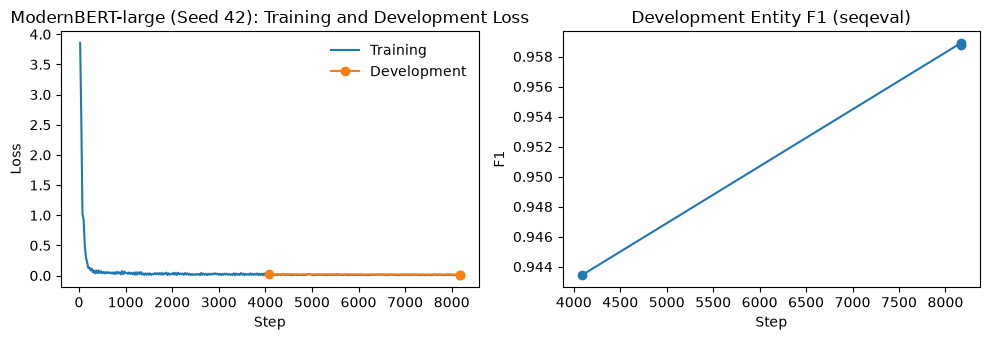

In [9]:
hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"], h["eval_f1"]) for h in hist if "eval_f1" in h]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
if tr:
    ax[0].plot(*zip(*tr), label="Training")
if ev:
    ax[0].plot([e[0] for e in ev], [e[1] for e in ev], "o-", label="Development")
    ax[1].plot([e[0] for e in ev], [e[2] for e in ev], "o-")
ax[0].set_title(f"{DISPLAY_NAME}: Training and Development Loss")
ax[0].set_xlabel("Step")
ax[0].set_ylabel("Loss")
ax[0].legend(frameon=False)
ax[1].set_title("Development Entity F1 (seqeval)")
ax[1].set_xlabel("Step")
ax[1].set_ylabel("F1")
plt.tight_layout()
if not SMOKE:
    plt.savefig(RESULTS / f"fig_training_{RUN_NAME}.png", dpi=150)
plt.show()

## 6. Sanity Check on an Unseen Sentence

In [10]:
from transformers import pipeline

ner = pipeline("token-classification", model=trainer.model, tokenizer=tokenizer, aggregation_strategy="simple",
               device=0 if torch.cuda.is_available() else -1)
sample = ("Dear Ms Priya Raman, your Medicare card 2123 45670 1 and TFN 123 456 782 were updated on 3 May 2024. "
          "Call 0412 345 678 or email priya.raman@example.com.au. Address: 14 Wattle St, Fitzroy VIC 3065.")
for ent in ner(sample):
    print(f"{ent['entity_group']:<12} {ent['score']:.2f}  {sample[ent['start']:ent['end']]}")

PERSON       1.00   Priya Raman
ID_NUMBER    1.00   2123 45670 1
ID_NUMBER    0.88   123 456 782
DATE         0.99   3 May 2024
PHONE        1.00   0412 345 678
EMAIL        1.00   priya.raman@example.com.au
ADDRESS      1.00   14 Wattle St
LOCATION     1.00   Fitzroy
LOCATION     1.00   VIC
ADDRESS      1.00   3065
